In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra

┌ Warning: Circular dependency detected. Precompilation will be skipped for:
│   SpecialFunctionsExt [1285c0f1-ff9f-5867-b66e-0f359bcf09ba]
│   GPUArrays [0c68f7d7-f131-5f86-a1c3-88cf8149b2d7]
│   LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
│   KernelAbstractions [63c18a36-062a-441e-b654-da1e3ab1ce7c]
│   CUDA [052768ef-5323-5732-b1bb-66c8b64840ba]
│   SparseArraysExt [85068d23-b5fb-53f1-8204-05c2aba6942f]
│   AtomixCUDAExt [13011619-4c7c-5ef0-948f-5fc81565cd05]
│   LinearAlgebraExt [66d79d19-2cc4-5b0b-ac7a-b340256d1ecd]
└ @ Pkg.API C:\Users\_s2220186\AppData\Local\Programs\Julia-1.10.7\share\julia\stdlib\v1.10\Pkg\src\API.jl:1279
[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a p

In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[5.864313059005935e-5 - 0.0032760596974582908im 0.000359188668811062 + 0.0007682204894975863im … -0.0009374124159730582 - 0.00015919185168467788im -0.0015871050062237254 - 0.0018133554917932927im; 0.004003837651020833 - 0.002261961917432848im -0.00022949290164708323 + 0.0013888777400451148im … 0.0009898425577473213 + 0.0009249729538615192im -0.0027111922605464376 - 0.000426996235640315im; 0.0011411031690564861 - 7.303141104284055e-5im 0.002419292218052065 - 0.0010502941326814112im … -8.91737222988164e-5 + 0.00047846751671594455im -0.003653502989423594 - 0.000579301490352122im;;; 0.0019826039634606224 - 0.001516916007910088im 0.0019882180478905855 - 0.0010348675679146063im … 0.00024952770668733884 + 4.146174361873052e-5im 0.0005770393185153058 - 0.0012332868137947938im; 0.0010404446394875185 - 0.0001287503268483458im 0.000870838245578247 - 0.0026838329641616135im … -0.0005140929139232979 - 0.0021337741646417184im

In [3]:
P=Onestep()
e=0.1
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)*e
W2=Generate_weight(hop)*e
W3=Generate_weight(hop)*e
W4=Generate_weight(hop)*e
W5=Generate_weight(hop)*e
W6=Generate_weight(hop)*e



9-element Vector{Spin_matrix}:
 [-0.04577919721872209 + 0.0im 0.12116219395960603 + 0.0im -0.22771408750325223 + 0.0im 0.09712715588862009 + 0.0im; -0.061109901125178646 + 0.0im -0.0787907233516709 + 0.0im -0.015214079621379563 + 0.0im 0.046550835965133125 + 0.0im; 0.02764707732226894 + 0.0im 0.06933822587618213 + 0.0im 0.18708722554500024 + 0.0im -0.15520321687748692 + 0.0im; -0.11793797415817756 + 0.0im 0.08160932125212524 + 0.0im 0.03391521692787737 + 0.0im 0.07955384576644896 + 0.0im]
 [-0.04699382398250199 + 0.0im -0.13964188299170788 + 0.0im 0.14918643607566429 + 0.0im 0.09253758089403608 + 0.0im; -0.1452174594633907 + 0.0im -0.05160037964399179 + 0.0im -0.066652007929161 + 0.0im -0.033956321880546786 + 0.0im; 0.07405982962985662 + 0.0im -0.01615141193712959 + 0.0im -0.01017077121969913 + 0.0im -0.025740475538181436 + 0.0im; 0.08460932534671928 + 0.0im 0.21316220811658476 + 0.0im -0.19099295021324125 + 0.0im -0.04357554363665223 + 0.0im]
 [-0.11897815608220966 + 0.0im -0.09465064

In [4]:
layer1=CPTC_Layer(hop,W1)
Norm=complexNormLayer()
layer2=PTC_Layer(hop,W2)
act=Softmax()
layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
layer3=Attention_Layer(CPTC_Layer(hop,W3),sqrt(length(x)),act,true)
layer4=PTC_Layer(hop,W4)
layer5=PTC_Layer(hop,W5)
layer6=PTC_Layer(hop,W6)
layers=[layer1,Norm,layer2,Norm,layer3,Norm,layer4]

7-element Vector{LMP.Layer_types.Layer}:
 Attention_Layer(CPTC_Layer(Spin_matrix[[-0.12452891288675683 + 0.0im 0.007107539810659369 + 0.0im 0.0524490132908411 + 0.0im -0.0947024358279116 + 0.0im; -0.0010362843947450508 + 0.0im -0.03788951474496147 + 0.0im -0.09405495387875079 + 0.0im -0.035261152218461905 + 0.0im; -0.17753233185365658 + 0.0im -0.0011744282718989703 + 0.0im 0.04358444881304522 + 0.0im 0.11063893562212386 + 0.0im; -0.04037700713723248 + 0.0im -0.041983498013542106 + 0.0im 0.026072321838268898 + 0.0im 0.12190269450039115 + 0.0im], [0.029044413831809498 + 0.0im 0.02992857690861821 + 0.0im 0.03817814947163492 + 0.0im -0.1711863513974806 + 0.0im; 0.1799517624362803 + 0.0im 0.09215897577351446 + 0.0im 0.033683876040280475 + 0.0im -0.09967622384203656 + 0.0im; -0.036477866755009906 + 0.0im 0.14743865352882254 + 0.0im -0.15307027043927057 + 0.0im -0.10588251803394853 + 0.0im; -0.03851513809257171 + 0.0im 0.10624419060050339 + 0.0im 0.08322139753306587 + 0.0im -0.047497058498597

In [5]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[3.776818587538238e-7 + 1.0149892916047276e-5im 6.604463104409875e-7 - 1.1728897294991353e-6im … 9.882363378598612e-6 + 6.062897022818587e-6im -6.472801198081294e-6 + 8.265445348539218e-6im; 5.588061160565517e-6 - 5.032963734598256e-6im -1.974947027447429e-6 - 8.229672298542727e-6im … -4.461649793974995e-6 + 2.4903437534819735e-6im 3.877609575223229e-6 + 4.4562141700859325e-6im; -6.494487953004391e-6 + 6.714972424925137e-7im 1.3018184558669689e-5 - 3.3535867003232066e-6im … -5.402407953244302e-6 + 4.3357712069740125e-6im -2.5819004294646835e-6 - 8.880489591050457e-6im;;; 1.0284192106139538e-6 + 5.360703838416636e-6im 1.2049223409995859e-5 - 6.125360575150465e-6im … -1.072339340014777e-5 - 7.159294135063783e-6im 6.783679982601831e-6 - 8.328137584298637e-7im; -4.4706662303427145e-6 - 1.6391015767204453e-6im -1.4131340654430807e-5 + 5.9918323733041445e-6im … -5.145142436231351e-6 + 4.050320335112864e-7im 2.92346560

In [6]:
opt=Adam()
opt.α=0.05

0.05

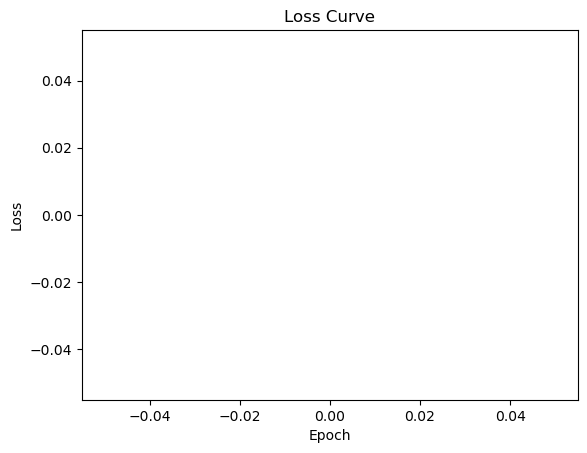

Epoch: 1, Loss: 89.97975746008002 + 0.0im
Epoch: 2, Loss: 68.06107792594506 + 0.0im
Epoch: 3, Loss: 22.263803729578072 + 0.0im
Epoch: 4, Loss: 29.790736547778664 + 0.0im
Epoch: 5, Loss: 34.88814459412576 + 0.0im
Epoch: 6, Loss: 19.615102670250664 + 0.0im
Epoch: 7, Loss: 20.72583483531268 + 0.0im
Epoch: 8, Loss: 20.18620687264551 + 0.0im
Epoch: 9, Loss: 12.95568696579372 + 0.0im
Epoch: 10, Loss: 8.90425892884958 + 0.0im
Epoch: 11, Loss: 8.026758237633345 + 0.0im
Epoch: 12, Loss: 7.281753289918037 + 0.0im
Epoch: 13, Loss: 5.938880738047293 + 0.0im
Epoch: 14, Loss: 4.738426437971391 + 0.0im
Epoch: 15, Loss: 3.9072537428506657 + 0.0im
Epoch: 16, Loss: 3.3824737561998655 + 0.0im
Epoch: 17, Loss: 3.1917849948861696 + 0.0im
Epoch: 18, Loss: 2.9963260743570426 + 0.0im
Epoch: 19, Loss: 2.725603769929797 + 0.0im
Epoch: 20, Loss: 2.423064364385421 + 0.0im
Epoch: 21, Loss: 2.199681322472405 + 0.0im
Epoch: 22, Loss: 2.048793899606962 + 0.0im
Epoch: 23, Loss: 2.0001747385440933 + 0.0im
Epoch: 24, Lo

In [ ]:
train(opt,layers,x,t,D,epochs=1000)

In [ ]:
opt.α=0.05

0.05

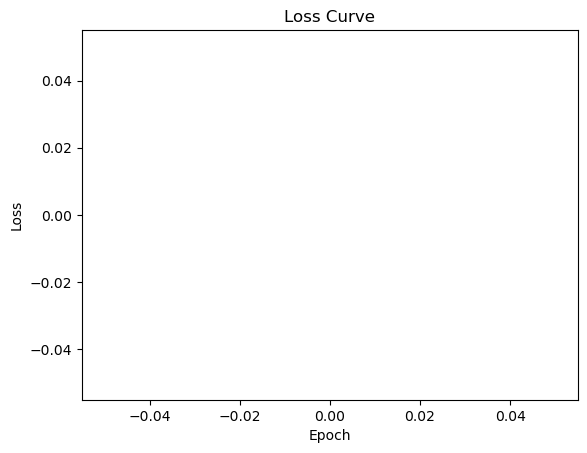

Epoch: 1, Loss: 0.008567788922148862 + 0.0im
Epoch: 2, Loss: 0.007911883391673435 + 0.0im
Epoch: 3, Loss: 0.008100696322266553 + 0.0im
Epoch: 4, Loss: 0.008730179504964039 + 0.0im
Epoch: 5, Loss: 0.009245966429504753 + 0.0im
Epoch: 6, Loss: 0.009610031928417747 + 0.0im
Epoch: 7, Loss: 0.009408652336933396 + 0.0im
Epoch: 8, Loss: 0.00925781211798945 + 0.0im
Epoch: 9, Loss: 0.009067155429908113 + 0.0im
Epoch: 10, Loss: 0.00880078555221541 + 0.0im
Epoch: 11, Loss: 0.008486525051904462 + 0.0im
Epoch: 12, Loss: 0.008397527207516105 + 0.0im
Epoch: 13, Loss: 0.00846622425331484 + 0.0im
Epoch: 14, Loss: 0.008692882610286492 + 0.0im
Epoch: 15, Loss: 0.008902169330338109 + 0.0im
Epoch: 16, Loss: 0.009275582594028145 + 0.0im
Epoch: 17, Loss: 0.008959770709205747 + 0.0im
Epoch: 18, Loss: 0.008770303865774471 + 0.0im
Epoch: 19, Loss: 0.008220819409866607 + 0.0im
Epoch: 20, Loss: 0.008622156271059288 + 0.0im
Epoch: 21, Loss: 0.008743301806183951 + 0.0im
Epoch: 22, Loss: 0.008496569496873458 + 0.0im


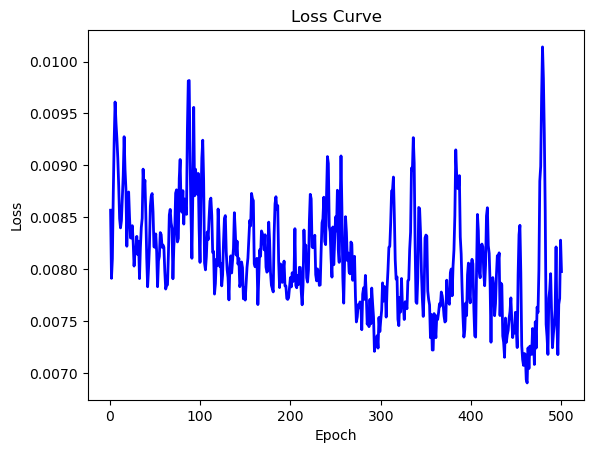

In [ ]:
train(opt,layers,x,t,D,epochs=500)

In [ ]:
opt.α=0.05

0.05